# 00 · Data Validation & Cleaning
**Project:** Classifying the 2026 LLM API Market: Price Tiers, Price Trends, and Budget-Based Model Selection
**Course:** ICT324 Data Warehousing & Data Mining · Team Straw Hats · CRISP-DM phase: *Data Understanding → Data Preparation*

### Why this notebook exists
Every later research question depends on this data being right:

| RQ | Needs |
|---|---|
| RQ1 Tiers (clustering) | one clean price and one comparable performance score per model |
| RQ2 Tier classification | clean model features (provider, open/closed, capability flags) |
| RQ3 Trend classification | clean, gap-free weekly price series |
| RQ4 Model selection | everything above, with no future information leaking into a backtest |

So before any modelling we **check** each table, **fix** what is wrong in a documented way, and **record** every check in a validation report.

### Rules we follow
1. Raw files are **never modified**. Every fix happens in memory, and results are written to new `clean_*.csv` files.
2. Each step has three parts: **what we check and why**, **the code**, and **what we found**.
3. Fixes are conservative. When a value is suspicious but possibly real, we **flag** it rather than delete it.

### Data
`ai_models.db` (SQLite) merges two Kaggle datasets by the same author:
- **Main:** [AI Models Pricing & Price History 2023–2026](https://www.kaggle.com/datasets/abirambharathisa/ai-models-and-api-pricing-2026-price-history) → `catalog_models`, `price_history`
- **Enrichment:** [LLM Benchmarks & Specs 2026](https://www.kaggle.com/datasets/abirambharathisa/llm-benchmarks-and-specs-2026-448-ai-models) → `models`, `benchmark_results`, `provider_offerings`, `labs`, `providers`

### How to run in Google Colab
Run the cells in order. The setup cell asks you to upload `ai_models.db`. If the file is on Google Drive, set `USE_DRIVE = True` and fix `DRIVE_PATH`. You can also upload the 5 CSV files to enable the optional CSV ↔ DB parity check.

## Step 1 · Setup
Import the libraries (all preinstalled on Colab), locate the database, and create a small helper `log_check()`. Each check calls it, and its records build the final **validation report** (Step 9).

In [1]:
import os, sys, re, sqlite3, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False                                   # set True to read from Google Drive
DRIVE_PATH = "/content/drive/MyDrive/ICT324/ai_models.db"

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        DB_PATH = DRIVE_PATH
    else:
        from google.colab import files
        DB_PATH = "ai_models.db"
        if not os.path.exists(DB_PATH):
            print("Upload ai_models.db (and optionally the 5 CSV files):")
            files.upload()
    CSV_DIR, OUT_DIR = ".", "clean"
else:                                               # local run from notebooks/
    DB_PATH, CSV_DIR, OUT_DIR = "../data/raw/ai_models.db", "../data/raw", "../data/processed"

os.makedirs(OUT_DIR, exist_ok=True)
assert os.path.exists(DB_PATH), f"Database not found at {DB_PATH}"
con = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)   # read-only: raw data stays untouched

report = []
def log_check(table, check, rows_affected, action="none", passed=None):
    # passed defaults to "no rows affected"
    report.append({"table": table, "check": check,
                   "passed": (rows_affected == 0) if passed is None else passed,
                   "rows_affected": int(rows_affected), "action": action})

print("DB:", DB_PATH, "| output dir:", OUT_DIR)

DB: ../data/raw/ai_models.db | output dir: ../data/processed


## Step 2 · Load all tables and get a first look
We load every table into a pandas DataFrame and look at its **shape** and **missing-value rate**. A high null rate is not automatically a problem: many optional columns, such as `price_per_image`, are null for text models by design. The table shows where to look closer.

In [2]:
TABLES = ["labs", "providers", "models", "benchmark_results",
          "provider_offerings", "catalog_models", "price_history"]
raw = {t: pd.read_sql(f"SELECT * FROM {t}", con) for t in TABLES}

overview = pd.DataFrame({
    "rows": {t: len(df) for t, df in raw.items()},
    "columns": {t: df.shape[1] for t, df in raw.items()},
    "cells_null_%": {t: round(df.isna().mean().mean() * 100, 1) for t, df in raw.items()},
})
overview

,rows,columns,cells_null_%
labs,47,2,9.6
providers,226,2,0.0
models,448,31,10.0
benchmark_results,1082,11,31.7
provider_offerings,8427,11,26.8
catalog_models,4403,31,23.5
price_history,167787,10,3.1


In [3]:
# Columns with any missing values, per table (top 8 by null rate)
for t, df in raw.items():
    nulls = (df.isna().mean() * 100).round(1)
    nulls = nulls[nulls > 0].sort_values(ascending=False).head(8)
    if len(nulls):
        print(f"\n{t}:"); print(nulls.to_string())


labs:
lab_country    19.1

models:
license                       87.5
weights_url                   62.1
structured_output             58.9
knowledge_cutoff              46.7
min_output_price_per_1m       10.0
median_input_price_per_1m     10.0
min_input_price_per_1m        10.0
median_output_price_per_1m    10.0

benchmark_results:
dataset          87.7
version          78.7
harness          76.1
variant          53.6
reported_date    48.5
metric            3.8

provider_offerings:
cache_write_price_per_1m    78.5
offering_name               44.5
context_window              44.4
max_output_tokens           44.4
base_model_id               36.7
cache_read_price_per_1m     35.6
output_price_per_1m          5.3
input_price_per_1m           5.3

catalog_models:
output_price_per_second             99.0
input_price_per_second              97.5
price_per_image                     92.6
batch_output_price_per_1m_tokens    92.1
batch_input_price_per_1m_tokens     91.7
deprecation_date         

**What we found:** All 7 tables load. Most nulls are in optional columns, such as per-image prices in the catalog, cache prices, `license` and `knowledge_cutoff`. The columns the analysis needs (model ids, prices, benchmark scores, weeks) are checked one by one in the steps below.

## Step 3 · Structural checks
These checks ask whether the database itself is sound:
- **Integrity check:** the SQLite file is not corrupted.
- **Foreign keys:** every reference, such as `benchmark_results.model_id → models.model_id`, points to a row that exists.
- **Primary-key uniqueness:** no duplicate keys, so joins later cannot multiply rows.
- **CSV ↔ DB parity** (if the CSVs were uploaded): the database contains every row of the source files.

In [4]:
integrity = con.execute("PRAGMA integrity_check").fetchone()[0]
fk_violations = con.execute("PRAGMA foreign_key_check").fetchall()
print("integrity_check:", integrity, "| foreign-key violations:", len(fk_violations))
log_check("database", "SQLite integrity_check", 0 if integrity == "ok" else 1)
log_check("database", "foreign-key violations", len(fk_violations))

PKS = {"labs": ["lab"], "providers": ["provider_id"], "models": ["model_id"],
       "catalog_models": ["model_id"], "provider_offerings": ["provider_id", "offering_id"],
       "price_history": ["week_start", "provider", "model_id"]}
for t, key in PKS.items():
    dups = raw[t].duplicated(subset=key).sum()
    print(f"{t:20s} key={key}  duplicate keys={dups}")
    log_check(t, f"primary key {key} unique", dups)

CSV_MAP = {"ai_models_2026.csv": "catalog_models", "ai_model_price_history.csv": "price_history",
           "llm_models.csv": "models", "llm_benchmarks.csv": "benchmark_results",
           "llm_provider_offerings.csv": "provider_offerings"}
for f, t in CSV_MAP.items():
    p = os.path.join(CSV_DIR, f)
    if os.path.exists(p):
        n_csv = len(pd.read_csv(p, low_memory=False))
        print(f"{f:30s} csv={n_csv:>7,}  db={len(raw[t]):>7,}  {'OK' if n_csv == len(raw[t]) else 'MISMATCH'}")
        log_check(t, f"row parity with {f}", abs(n_csv - len(raw[t])))
    else:
        print(f"{f}: not uploaded, parity check skipped")

integrity_check: ok | foreign-key violations: 0
labs                 key=['lab']  duplicate keys=0
providers            key=['provider_id']  duplicate keys=0
models               key=['model_id']  duplicate keys=0
catalog_models       key=['model_id']  duplicate keys=0
provider_offerings   key=['provider_id', 'offering_id']  duplicate keys=0
price_history        key=['week_start', 'provider', 'model_id']  duplicate keys=0
ai_models_2026.csv             csv=  4,403  db=  4,403  OK
ai_model_price_history.csv     csv=167,787  db=167,787  OK
llm_models.csv                 csv=    448  db=    448  OK
llm_benchmarks.csv             csv=  1,082  db=  1,082  OK
llm_provider_offerings.csv     csv=  8,427  db=  8,427  OK


**What we found:** The file is not corrupted, there are no broken foreign keys and no duplicate primary keys, and the DB row counts match the CSV files exactly. The structure is sound, so the remaining issues are about *content*.

## Step 4 · `models` table: specs and prices of benchmark-side models
This table supplies the **features** (lab, open weights, capabilities, context window) and the **price summary** (min and median price across providers) for RQ1 and RQ2.

### 4a · Validity checks
- Duplicate model names (the same model listed twice)
- Release dates: valid `YYYY-MM-DD` format and not in the future
- Prices: no negative values, and min price ≤ median price
- `n_benchmarks` agrees with the actual rows in `benchmark_results`
- `n_providers` agrees with the actual provider offerings

In [5]:
m = raw["models"].copy()
AS_OF = pd.Timestamp(raw["price_history"]["week_start"].max())   # last week in the data
print("Data as-of week:", AS_OF.date())

dup_names = m["model_name"].str.lower().duplicated().sum()
rel = pd.to_datetime(m["release_date"], format="%Y-%m-%d", errors="coerce")
TODAY = pd.Timestamp.today().normalize()
bad_dates, future = rel.isna().sum(), (rel > TODAY).sum()
print("models released after the price-history as-of week:",
      m.loc[rel > AS_OF + pd.Timedelta(days=6), ["model_id", "release_date"]].values.tolist())
price_cols = ["min_input_price_per_1m", "median_input_price_per_1m",
              "min_output_price_per_1m", "median_output_price_per_1m"]
negative = (m[price_cols] < 0).any(axis=1).sum()
min_gt_med = ((m.min_input_price_per_1m > m.median_input_price_per_1m) |
              (m.min_output_price_per_1m > m.median_output_price_per_1m)).sum()
nb_actual = raw["benchmark_results"].groupby("model_id").size()
nb_mismatch = (m["n_benchmarks"] != m["model_id"].map(nb_actual).fillna(0)).sum()
offers = raw["provider_offerings"].dropna(subset=["base_model_id"])
np_rows = m["model_id"].map(offers.groupby("base_model_id").size()).fillna(0)
np_dist = m["model_id"].map(offers.groupby("base_model_id")["provider_id"].nunique()).fillna(0)

checks = {"duplicate model names": dup_names, "invalid release_date format": bad_dates,
          "release_date after today": future, "negative prices": negative,
          "min price > median price": min_gt_med, "n_benchmarks mismatch": nb_mismatch,
          "n_providers != offering rows": (m.n_providers != np_rows).sum(),
          "n_providers != distinct providers": (m.n_providers != np_dist).sum()}
for k, v in checks.items():
    print(f"{k:38s} {v}")
for k in ["duplicate model names", "invalid release_date format", "release_date after today",
          "negative prices", "min price > median price", "n_benchmarks mismatch",
          "n_providers != distinct providers"]:
    log_check("models", k, checks[k])
print("\nrelease_date_precision:", m.release_date_precision.value_counts().to_dict())

Data as-of week: 2026-09-28
models released after the price-history as-of week: [['mistral/mistral-large-4', '2026-10-06']]


duplicate model names                  0
invalid release_date format            0
release_date after today               0
negative prices                        0
min price > median price               0
n_benchmarks mismatch                  0
n_providers != offering rows           176
n_providers != distinct providers      0

release_date_precision: {'day': 439, 'month': 9}


**What we found:** All validity checks pass. The benchmark-side snapshot is slightly **newer** than the price history: a model released in October 2026 has no weekly prices yet. That is expected, but it matters when the two datasets are joined. One more check looks like a failure but is not: `n_providers` differs from the number of *offering rows*, yet it equals the number of *distinct providers*. A provider can sell the same model more than once (for example with different context sizes), so `n_providers` is correct. A few release dates are known only to the month (`release_date_precision = month`). They are stored as the first day of that month, which is precise enough for this project.

### 4b · Keep only text LLMs
The project studies **text LLM APIs**. The table also contains image, video and audio generators, embedding models, rerankers, speech-to-text models and safety classifiers. They are priced differently and are not chat models, so they would distort the tiers. A model counts as a text LLM if:
1. its output includes `text`, **and**
2. it accepts text input, **and**
3. its id does not match a non-chat model family (embed, rerank, guard/safeguard, whisper, transcribe, tts).

In [6]:
NON_LLM = r"embed|rerank|guard|whisper|transcrib|tts"
m["text_output"] = m["output_modalities"].fillna("").str.contains("text")
m["non_llm_name"] = m["model_id"].str.contains(NON_LLM, case=False)
m["is_text_llm"] = m.text_output & (m.input_text == 1) & ~m.non_llm_name

dropped = m.loc[~m.is_text_llm, ["model_id", "output_modalities", "input_text"]]
print(f"Dropped {len(dropped)} non-text-LLM models; {m.is_text_llm.sum()} remain.\n")
print(dropped.to_string(index=False))
log_check("models", "non-text-LLM models removed", len(dropped), "dropped", passed=True)

Dropped 37 non-text-LLM models; 411 remain.

                                    model_id output_modalities  input_text
             xai/grok-imagine-video-1.5-lite             video           1
                      alibaba/qwen-image-2.1             image           1
                  openai/gpt-image-2.5-flare             image           1
               openai/gpt-image-2.5-sunburst             image           1
           google/gemini-3.5-transcribe-live              text           0
                  xai/grok-imagine-image-2.0             image           1
                      xai/grok-voice-stt-1.0              text           0
                 bytedance-seed/seedance-2.5       video,audio           1
                          minimax/MiniMax-H3       video,audio           1
                      xai/grok-voice-tts-1.0             audio           1
            google/gemini-omni-flash-preview             video           1
    google/gemini-3.5-live-translate-preview        aud

**What we found:** 37 models are not text LLMs (image/video/audio generators, embeddings, rerankers, guards, speech-to-text), and we drop them. The rest are text LLMs.

### 4c · Prices and context window
- A **median price of 0 or null** means we cannot place the model on a price axis. Common causes are free preview models or models with no provider listing. We **keep** these models but mark them `has_valid_price = False`, so price-based analyses skip them.
- **Input price > output price** is unusual for chat models and often signals a non-chat model. We list the remaining cases for review.
- **Context window = 0** is impossible, so we set it to missing (NaN).

In [7]:
m = m[m.is_text_llm].copy()
m["has_valid_price"] = (m.median_input_price_per_1m > 0) & (m.median_output_price_per_1m > 0)
print("has_valid_price:", m.has_valid_price.value_counts().to_dict())
log_check("models", "text LLMs without a valid (>0) median price", (~m.has_valid_price).sum(),
          "flagged has_valid_price=False", passed=True)

inv = m[m.has_valid_price & (m.median_input_price_per_1m > m.median_output_price_per_1m)]
print(f"\nInput price > output price among priced text LLMs: {len(inv)}")
print(inv[["model_id", "median_input_price_per_1m", "median_output_price_per_1m"]].to_string(index=False))
log_check("models", "input price > output price (text LLMs)", len(inv), "reviewed")

bad_ctx = (m.context_window.isna() | (m.context_window <= 0)).sum()
m.loc[m.context_window <= 0, "context_window"] = np.nan
print(f"\ncontext_window missing or 0 → NaN: {bad_ctx}")
log_check("models", "context_window null or 0", bad_ctx, "set to NaN", passed=True)

has_valid_price: {True: 356, False: 55}

Input price > output price among priced text LLMs: 0
Empty DataFrame
Columns: [model_id, median_input_price_per_1m, median_output_price_per_1m]
Index: []

context_window missing or 0 → NaN: 1


**What we found:** Among priced text LLMs, none has an input price above its output price. The raw cases were embedding, speech and guard models (removed in 4b) plus two "decision" models with an output price of 0, which `has_valid_price` already excludes. Text LLMs with no valid price stay in the table but are flagged, and a few zero context windows are now missing values.

## Step 5 · `benchmark_results`: the performance side
Benchmark scores become the **performance axis** for the tiers (RQ1) and the **task score** in the value ranking (RQ4). This table is in *long format*: one row per (model, benchmark, metric, variant).

### 5a · Spelling variants of the same benchmark
If one benchmark is spelled two ways, it splits into two smaller benchmarks, and each covers fewer models. We build a **matching key**: normalize Unicode (curly `’` → straight `'`), lower-case, and treat hyphens and spaces the same. Names that share a key are merged, and the most common spelling becomes the canonical name. Version numbers stay part of the key, so `Terminal Bench 2.0` and `Terminal-Bench 2.1` remain different benchmarks.

In [8]:
b = raw["benchmark_results"].copy()

def bench_key(name):
    s = unicodedata.normalize("NFKC", name).replace("’", "'").replace("‘", "'")
    s = re.sub(r"[-_\s]+", " ", s.lower()).strip()
    return s

b["bench_key"] = b["benchmark"].map(bench_key)
canonical = (b.groupby(["bench_key", "benchmark"]).size().reset_index(name="n")
               .sort_values(["bench_key", "n"], ascending=[True, False])
               .drop_duplicates("bench_key").set_index("bench_key")["benchmark"])
b["benchmark_clean"] = b["bench_key"].map(canonical)

aliases = (b.groupby("bench_key")["benchmark"].unique().loc[lambda s: s.str.len() > 1])
alias_table = pd.DataFrame({"canonical": canonical[aliases.index],
                            "merged_spellings": aliases.map(lambda v: " | ".join(v))})
n_renamed = (b.benchmark != b.benchmark_clean).sum()
print(f"Distinct benchmarks: {b.benchmark.nunique()} → {b.benchmark_clean.nunique()}  "
      f"({n_renamed} rows renamed)")
log_check("benchmark_results", "benchmark name spelling variants", n_renamed, "merged to canonical name", passed=True)
alias_table

Distinct benchmarks: 180 → 169  (15 rows renamed)


,canonical,merged_spellings
bench_key,,
claw eval,Claw-eval,Claw-Eval | Claw-eval
gdp.pdf,GDP.PDF,GDP.PDF | GDP.pdf
humanity's last exam,Humanity's Last Exam,Humanity's Last Exam | Humanity’s Last Exam
mls bench lite,MLS-Bench-Lite,MLS Bench Lite | MLS-Bench-Lite
mmmu pro,MMMU Pro,MMMU Pro | MMMU-Pro
swe bench pro,SWE-Bench Pro,SWE Bench Pro | SWE-Bench Pro | SWE-bench Pro
swe marathon,SWE Marathon,SWE Marathon | SWE-Marathon
terminal bench 2.1,Terminal-Bench 2.1,Terminal Bench 2.1 | Terminal-Bench 2.1
terminal bench science,Terminal-Bench-Science,Terminal-Bench Science | Terminal-Bench-Science


**What we found:** The table lists each group of spellings that were merged. Review it once: every row should be the *same* benchmark written differently.

### 5b · Metric labels and direction
- Some rows have an **empty metric**. We fill them with `"unspecified"` so they still group together consistently.
- Nearly all metrics are *higher is better* (accuracy, pass@1, Elo, …). Any **lower-is-better** metric, such as edit distance, would turn a percentile ranking upside down, so we flag it with `higher_is_better = False` and leave it out of composite scores.

In [9]:
b["metric_clean"] = b["metric"].fillna("").str.strip().str.lower().replace("", "unspecified")
n_blank = (b.metric_clean == "unspecified").sum()
LOWER_BETTER = r"edit distance|error|latency|cost"
b["higher_is_better"] = ~b.metric_clean.str.contains(LOWER_BETTER)
print("empty metric → 'unspecified':", n_blank)
print("lower-is-better rows:", (~b.higher_is_better).sum(),
      b.loc[~b.higher_is_better, ["benchmark_clean", "metric_clean"]].drop_duplicates().values.tolist())
log_check("benchmark_results", "empty metric label", n_blank, "filled 'unspecified'", passed=True)
log_check("benchmark_results", "lower-is-better metric", (~b.higher_is_better).sum(),
          "flagged higher_is_better=False", passed=True)

pct = b.metric_clean.isin(["accuracy", "pass@1", "success rate", "resolve rate",
                           "percent correct", "resolved", "percent", "pass rate"])
out_of_range = (pct & ((b.score < 0) | (b.score > 100))).sum()
fraction_scale = (pct & (b.score <= 1)).sum()
print("percent-type scores outside 0–100:", out_of_range, "| on 0–1 scale:", fraction_scale)
log_check("benchmark_results", "percent score outside 0-100", out_of_range)
log_check("benchmark_results", "percent score on 0-1 scale", fraction_scale)

empty metric → 'unspecified': 41
lower-is-better rows: 2 [['OmniDocBench', 'overall edit distance']]
percent-type scores outside 0–100: 0 | on 0–1 scale: 0


**What we found:** No percent score falls outside 0–100, and none was recorded as a 0–1 fraction, so the scales are consistent. Only the edit-distance metric is lower-is-better.

### 5c · Several scores for one (model, benchmark, metric)
A lab often reports the same benchmark under several settings, for example *with tools* and *without tools*, or *max effort* and *default*. Counting all of them would give that model extra weight. We keep **one score per (model, benchmark, metric)**, namely the **best reported** score (the highest, or the lowest for lower-is-better metrics), because labs usually headline that setting. We also store how many variants there were and which one we kept.

In [10]:
grp = ["model_id", "benchmark_clean", "metric_clean"]
dup_groups = b.duplicated(subset=grp, keep=False)
print("rows in duplicate groups:", dup_groups.sum(), "| groups:", b[dup_groups].groupby(grp).ngroups)
display(b.loc[dup_groups, grp + ["variant", "score"]].sort_values(grp).head(10))

b["_rank_score"] = np.where(b.higher_is_better, b.score, -b.score)
b["n_variants"] = b.groupby(grp)["score"].transform("size")
b_best = (b.sort_values("_rank_score", ascending=False)
            .drop_duplicates(subset=grp, keep="first").drop(columns="_rank_score"))
log_check("benchmark_results", "multiple variants per (model, benchmark, metric)",
          len(b) - len(b_best), "kept best score", passed=True)
print(f"rows: {len(b)} → {len(b_best)}")

rows in duplicate groups: 185 | groups: 81


,model_id,benchmark_clean,metric_clean,variant,score
154,alibaba/qwen3.8-27b,BabyVision,score,with code interpreter,85.6
156,alibaba/qwen3.8-27b,BabyVision,score,without code interpreter,65.7
186,alibaba/qwen3.8-27b,CharXiv Reasoning,score,with code interpreter,90.2
195,alibaba/qwen3.8-27b,CharXiv Reasoning,score,without code interpreter,83.7
587,alibaba/qwen3.8-27b,MathVision,score,with code interpreter,94.6
589,alibaba/qwen3.8-27b,MathVision,score,without code interpreter,90.0
185,alibaba/qwen3.8-flash-next,CharXiv Reasoning,score,with code interpreter,90.6
193,alibaba/qwen3.8-flash-next,CharXiv Reasoning,score,without code interpreter,84.6
586,alibaba/qwen3.8-flash-next,MathVision,score,with code interpreter,95.7
588,alibaba/qwen3.8-flash-next,MathVision,score,without code interpreter,90.6


rows: 1082 → 978


**What we found:** Some (model, benchmark, metric) groups had several variant rows. Each group now has a single score, the best one, and `n_variants` records how many there were.

### 5d · Dates and links to `models`
- **Reported before release:** for some rows, `reported_date` comes before the model's `release_date`. This usually means a pre-release evaluation, or a model whose listed release date is its *GA* date. It is not an error, but it matters for the **RQ4 backtest**: a score is "known" only from its reported date. We add a `reported_before_release` flag.
- **Scores of non-text models** are dropped together with those models (Step 4b).

In [11]:
rel_map = raw["models"].set_index("model_id")["release_date"]
b_best["reported_before_release"] = (pd.to_datetime(b_best.reported_date) <
                                     pd.to_datetime(b_best.model_id.map(rel_map)))
n_early = b_best.reported_before_release.sum()
print("reported_date < release_date:", n_early)
log_check("benchmark_results", "reported_date before release_date", n_early,
          "flagged (pre-release eval)", passed=True)

keep = b_best.model_id.isin(m.model_id)
print("rows belonging to non-text models dropped:", (~keep).sum())
log_check("benchmark_results", "rows of non-text-LLM models", (~keep).sum(), "dropped", passed=True)
bench = b_best[keep].drop(columns=["bench_key"]).reset_index(drop=True)
print("clean benchmark rows:", len(bench), "| models with ≥1 score:", bench.model_id.nunique())

reported_date < release_date: 31
rows belonging to non-text models dropped: 1
clean benchmark rows: 977 | models with ≥1 score: 156


## Step 6 · `catalog_models`: the pricing catalog (main dataset)
This table lists every model **per provider** with its current price and capability flags. It feeds RQ3 and RQ4 and is also the target of the later name join with `models`.

### 6a · Keep text modes
`mode` tells us what kind of API the entry is. We keep the text-generation modes `chat`, `responses` and `completion` and drop image generation, embeddings, audio, video and so on.

In [12]:
c = raw["catalog_models"].copy()
print(c["mode"].value_counts().to_string())
TEXT_MODES = ["chat", "responses", "completion"]
n_before = len(c)
c = c[c["mode"].isin(TEXT_MODES)].copy()
print(f"\nkeep text modes: {n_before} → {len(c)}")
log_check("catalog_models", "non-text modes", n_before - len(c), "dropped", passed=True)

mode
chat                   3340
image_generation        405
embedding               148
responses               143
audio_transcription      93
realtime                 51
video_generation         45
audio_speech             40
completion               34
image_edit               31
rerank                   27
search                   23
ocr                      20
moderation                3

keep text modes: 4403 → 3517


### 6b · Regional and variant duplicates
Some providers list one model several times under regional ids, for example `azure/gpt-4.1`, `azure/eu/gpt-4.1` and `azure/us/gpt-4.1`. These are the **same model**, sometimes with a small regional surcharge. If all copies stay, that model counts several times in every statistic. We keep **one row per (provider, model name, mode)**, the one with the **shortest id** (the global, base entry), and we report how often the copies disagree on price.

In [13]:
c["name_key"] = c["model_name"].str.lower().str.strip()
key = ["provider", "name_key", "mode"]
dup_mask = c.duplicated(subset=key, keep=False)
groups = c[dup_mask].groupby(key)
price_differs = groups["input_price_per_1m_tokens"].nunique().gt(1).sum()
print(f"duplicate groups: {groups.ngroups} ({dup_mask.sum()} rows); groups whose copies differ in price: {price_differs}")
display(c.loc[dup_mask, ["provider", "model_id", "mode", "input_price_per_1m_tokens",
                         "output_price_per_1m_tokens"]].sort_values(["provider", "model_id"]).head(9))

c["_idlen"] = c.model_id.str.len()
n_before = len(c)
c = c.sort_values("_idlen").drop_duplicates(subset=key, keep="first").drop(columns="_idlen")
log_check("catalog_models", "regional/variant duplicates per (provider, name, mode)",
          n_before - len(c), "kept base (shortest id)", passed=True)
print(f"rows: {n_before} → {len(c)}")

duplicate groups: 310 (883 rows); groups whose copies differ in price: 206


,provider,model_id,mode,input_price_per_1m_tokens,output_price_per_1m_tokens
2650,azure,azure/computer-use-preview,chat,3.00,12.00
2647,azure,azure/eu/codex-mini,chat,1.65,6.60
2651,azure,azure/eu/computer-use-preview,chat,3.30,13.20
2728,azure,azure/eu/gpt-4.1,chat,2.20,8.80
2741,azure,azure/eu/gpt-4.1-mini,chat,0.44,1.76
2752,azure,azure/eu/gpt-4.1-nano,chat,0.11,0.44
2773,azure,azure/eu/gpt-4o-2024-05-13,chat,5.50,16.50
2778,azure,azure/eu/gpt-4o-2024-08-06,chat,2.75,11.00
2786,azure,azure/eu/gpt-4o-2024-11-20,chat,2.75,11.00


rows: 3517 → 2944


### 6c · Missing, free and deprecated entries
- **Null price:** the entry cannot be priced, so we drop it.
- **Zero price:** free or preview tiers. We keep these but flag `is_free`, since a 0 would break log-price features and value = score ÷ price.
- **Deprecated:** the entry has a `deprecation_date` on or before the as-of week. We flag it with `is_deprecated` rather than delete it, because the RQ4 backtest needs to know which models were available *at the time*.

In [14]:
null_price = c.input_price_per_1m_tokens.isna() | c.output_price_per_1m_tokens.isna()
print("null input or output price:", null_price.sum())
log_check("catalog_models", "null input/output price", null_price.sum(), "dropped", passed=True)
c = c[~null_price].copy()

c["is_free"] = (c.input_price_per_1m_tokens == 0) & (c.output_price_per_1m_tokens == 0)
dep = pd.to_datetime(c.deprecation_date.replace("", np.nan), errors="coerce")
c["is_deprecated"] = dep.notna() & (dep <= AS_OF)
print("free (0/0):", c.is_free.sum(), "| deprecated by as-of week:", c.is_deprecated.sum(),
      "| future deprecation scheduled:", (dep > AS_OF).sum())
log_check("catalog_models", "free (zero-price) entries", c.is_free.sum(), "flagged is_free", passed=True)
log_check("catalog_models", "deprecated entries", c.is_deprecated.sum(), "flagged is_deprecated", passed=True)
print("clean catalog rows:", len(c))

null input or output price: 141
free (0/0): 97 | deprecated by as-of week: 111 | future deprecation scheduled: 248
clean catalog rows: 2803


## Step 7 · `price_history`: weekly price series (input to RQ3)
Each **series** is one (provider, model) pair observed weekly from 2023-09 to 2026-09. Trend labels (falling, stable, rising) are computed from these series, so a single bad week can turn a *stable* model into a *rising* one. Order matters:

1. Keep text modes and drop rows with missing prices
2. Check the calendar (all weeks are Mondays, and there are few missing weeks overall)
3. Repair **one-week spikes**
4. Flag **extreme jumps**
5. Fill **gaps inside** a series
6. Mark which series are long enough for trend analysis

In [15]:
ph = raw["price_history"].copy()
ph["week_start"] = pd.to_datetime(ph.week_start)
n0 = len(ph)
ph = ph[ph["mode"].isin(TEXT_MODES)]
log_check("price_history", "non-text modes", n0 - len(ph), "dropped", passed=True)

null_p = ph.input_price_per_1m_tokens.isna() | ph.output_price_per_1m_tokens.isna()
print(f"text-mode rows: {len(ph):,} | rows with a null price: {null_p.sum():,}")
log_check("price_history", "null input/output price rows", null_p.sum(), "dropped", passed=True)
ph = ph[~null_p].copy()

non_monday = (ph.week_start.dt.day_of_week != 0).sum()
all_weeks = pd.date_range(ph.week_start.min(), ph.week_start.max(), freq="W-MON")
missing_weeks = all_weeks.difference(ph.week_start.unique())
print("non-Monday week_start:", non_monday, "| calendar weeks missing from the whole table:",
      [d.date().isoformat() for d in missing_weeks])
log_check("price_history", "week_start not a Monday", non_monday)
log_check("price_history", "calendar weeks missing in whole table", len(missing_weeks),
          "noted (gap-fill covers them)", passed=True)

text-mode rows: 158,113 | rows with a null price: 1,031


non-Monday week_start: 0 | calendar weeks missing from the whole table: ['2023-10-02', '2023-12-18']


### 7a · One-week spikes (A → B → A)
If a price goes from A to B and returns to **exactly A** the next week, it is almost always a scraping or data-entry glitch. A real price cut does not reverse itself after seven days. We set the middle week back to A, separately for input and output prices, and record each repair in `spike_fixed`.

In [16]:
SER = ["provider", "model_id"]
ph = ph.sort_values(SER + ["week_start"]).reset_index(drop=True)
ph["spike_fixed"] = False
for col in ["input_price_per_1m_tokens", "output_price_per_1m_tokens"]:
    g = ph.groupby(SER)[col]
    prev, nxt = g.shift(1), g.shift(-1)
    spike = (prev == nxt) & (ph[col] != prev) & prev.notna()
    print(f"{col}: {spike.sum()} one-week spikes repaired")
    ph.loc[spike, col] = prev[spike]
    ph.loc[spike, "spike_fixed"] = True
log_check("price_history", "one-week price spikes (A→B→A)", ph.spike_fixed.sum(), "reverted to A", passed=True)

input_price_per_1m_tokens: 32 one-week spikes repaired
output_price_per_1m_tokens: 33 one-week spikes repaired


### 7b · Extreme jumps (> 10× week-to-week)
A price that changes more than 10× in one week *might* be real (for example a launch-promo price ending) or might be an error such as a misplaced decimal point (33.0 vs 3.3). We cannot tell automatically, so we **flag** these rows (`extreme_jump`) and plot a few for manual review. RQ3 can then be run with and without them.

extreme week-to-week jumps: 34


,provider,model_id,week_start,input_price_per_1m_tokens
21457,azure_ai,azure_ai/grok-code-fast-1,2026-01-12,0.20
44855,bedrock_converse,us.anthropic.claude-sonnet-4-5-20250929-v1:0,2025-10-06,3.30
47862,cohere,command,2024-09-09,1.00
48089,cohere,command-nightly,2024-09-09,1.00
48353,cohere_chat,command-light,2024-09-09,0.30
72759,gemini,gemini/gemini-1.5-pro-exp-0827,2024-09-09,0.00
77675,groq,groq/llama-3.1-8b-instant,2024-10-07,0.05
87379,moonshot,moonshot/kimi-thinking-preview,2025-12-01,0.60
89175,nlp_cloud,chatdolphin,2024-02-12,0.50
89332,nlp_cloud,dolphin,2024-02-12,0.50


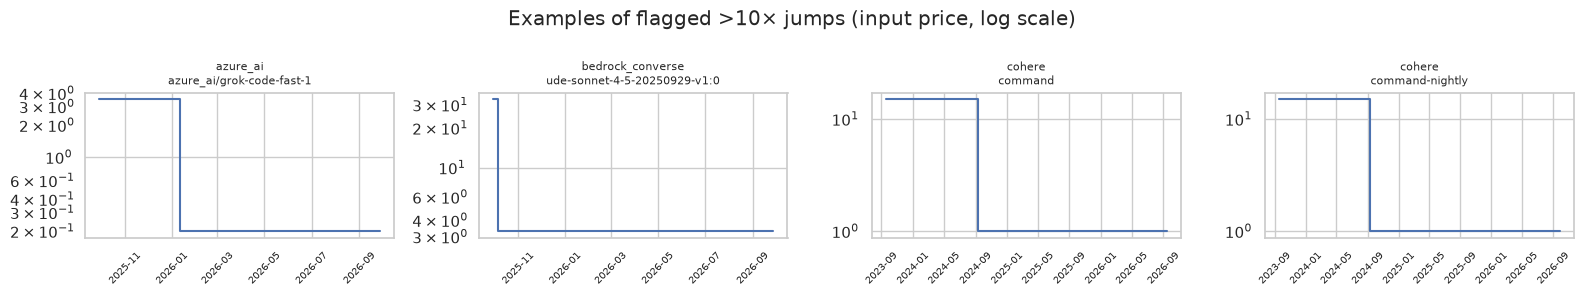

In [17]:
g = ph.groupby(SER)["input_price_per_1m_tokens"]
ratio = ph.input_price_per_1m_tokens / g.shift(1)
ph["extreme_jump"] = (g.shift(1) > 0) & ((ratio > 10) | (ratio < 0.1))
print("extreme week-to-week jumps:", ph.extreme_jump.sum())
log_check("price_history", "extreme week-to-week jump (>10x)", ph.extreme_jump.sum(),
          "flagged extreme_jump", passed=True)
jumps = ph.loc[ph.extreme_jump, SER + ["week_start", "input_price_per_1m_tokens"]]
display(jumps.head(10))

ex = jumps.drop_duplicates(SER).head(4)
fig, axes = plt.subplots(1, len(ex), figsize=(4 * len(ex), 3), squeeze=False)
for ax, (_, r) in zip(axes[0], ex.iterrows()):
    s = ph[(ph.provider == r.provider) & (ph.model_id == r.model_id)]
    ax.step(s.week_start, s.input_price_per_1m_tokens, where="post")
    ax.set_title(f"{r.provider}\n{r.model_id[-28:]}", fontsize=8); ax.set_yscale("log")
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
fig.suptitle("Examples of flagged >10× jumps (input price, log scale)"); plt.tight_layout(); plt.show()

### 7c · Gaps inside a series
Some series skip weeks. Trend features such as *weeks since last change* need one row per week. API prices change only when a provider announces a change, so a missing week most likely had the **same price as the week before**, and we **forward-fill** it. We fill only *between* a series' first and last observed week. We never extend a series past its last observation, because that would invent data, for example for a delisted model. Filled rows get `imputed = True`.

In [18]:
span = ph.groupby(SER)["week_start"].agg(["min", "max", "size"])
span["expected"] = ((span["max"] - span["min"]).dt.days // 7) + 1
gappy = span[span["size"] < span["expected"]]
print(f"series: {len(span):,} | series with internal gaps: {len(gappy):,} | "
      f"missing weekly rows: {(gappy.expected - gappy['size']).sum():,}")

gappy_keys = set(gappy.index)
is_gappy = pd.Series(list(zip(ph.provider, ph.model_id))).isin(gappy_keys).values
parts = []
for _, df in ph[is_gappy].groupby(SER):
    full = pd.date_range(df.week_start.min(), df.week_start.max(), freq="W-MON")
    out = df.set_index("week_start").reindex(full)
    out["imputed"] = out["model_id"].isna()
    out = out.ffill()                                   # carry last known price forward
    out.loc[out.imputed, ["spike_fixed", "extreme_jump"]] = False   # flags belong to real rows only
    out.index.name = "week_start"
    parts.append(out.reset_index())
filled = pd.concat(parts, ignore_index=True) if parts else ph.iloc[0:0]
rest = ph[~is_gappy].assign(imputed=False)
ph = pd.concat([rest, filled], ignore_index=True).sort_values(SER + ["week_start"]).reset_index(drop=True)
ph[["spike_fixed", "extreme_jump", "imputed"]] = ph[["spike_fixed", "extreme_jump", "imputed"]].astype(bool)
print("rows imputed by forward-fill:", ph.imputed.sum(), "| total rows:", f"{len(ph):,}")
log_check("price_history", "series with internal weekly gaps", len(gappy), "forward-filled inside series", passed=True)

series: 4,156 | series with internal gaps: 324 | missing weekly rows: 4,990


rows imputed by forward-fill: 4990 | total rows: 162,072


### 7d · Series length and catalog link
- A trend needs history. We mark series with **at least 8 weeks** (about two months) as `eligible_for_trend`. Shorter ones are new listings that RQ3 cannot label reliably.
- We also report how many rows link to a `catalog_models` entry through `catalog_model_id`. The rest belong to models that are no longer listed in the current catalog.

In [19]:
MIN_WEEKS = 8
slen = ph.groupby(SER)["week_start"].transform("size")
ph["series_weeks"] = slen
ph["eligible_for_trend"] = slen >= MIN_WEEKS
n_series = ph.groupby(SER).ngroups
n_short = ph.loc[~ph.eligible_for_trend].groupby(SER).ngroups
print(f"series: {n_series:,} | shorter than {MIN_WEEKS} weeks: {n_short:,} | eligible: {n_series - n_short:,}")
log_check("price_history", f"series shorter than {MIN_WEEKS} weeks", n_short,
          "flagged eligible_for_trend=False", passed=True)

changed = ph.groupby(SER).agg(ni=("input_price_per_1m_tokens", "nunique"),
                              no=("output_price_per_1m_tokens", "nunique"))
print("series with at least one price change:", ((changed.ni > 1) | (changed.no > 1)).sum())

linked = ph.catalog_model_id.notna()
print(f"rows linked to catalog_models: {linked.sum():,} / {len(ph):,} ({linked.mean():.1%})")
log_check("price_history", "rows without catalog_model_id link", (~linked).sum(),
          "noted (delisted models; name join later)", passed=True)

series: 4,156 | shorter than 8 weeks: 1,526 | eligible: 2,630
series with at least one price change: 475
rows linked to catalog_models: 127,608 / 162,072 (78.7%)


## Step 8 · `provider_offerings`: per-provider offers of benchmarked models
This table tells us *who sells which benchmarked model at what price*. RQ4 needs it to recommend a concrete provider. We check status values, zero prices, the link to `models`, and price sanity.

In [20]:
o = raw["provider_offerings"].copy()
print("status:", o.status.value_counts().to_dict())
zero = (o.input_price_per_1m == 0) & (o.output_price_per_1m == 0)
neg = (o[["input_price_per_1m", "output_price_per_1m"]] < 0).any(axis=1).sum()
nullp = o.input_price_per_1m.isna().sum()
linked = o.base_model_id.notna()
print(f"zero-price offers: {zero.sum()} | negative: {neg} | null price: {nullp} | "
      f"linked to a model: {linked.sum()} / {len(o)} ({linked.mean():.1%})")
log_check("provider_offerings", "negative price", neg)
log_check("provider_offerings", "zero-price offers", zero.sum(), "flagged is_free", passed=True)
log_check("provider_offerings", "offers not linked to a model", (~linked).sum(),
          "kept (unbenchmarked models)", passed=True)
o["is_free"] = zero
o["is_text_llm"] = o.base_model_id.isin(m.model_id)
offerings = o

status: {'active': 8094, 'deprecated': 261, 'beta': 72}
zero-price offers: 645 | negative: 0 | null price: 446 | linked to a model: 5333 / 8427 (63.3%)


## Step 9 · Is there enough data for the analysis?
Clean data is not enough. There also has to be **enough** of it. RQ1 needs models that have **both** a valid price **and** at least one benchmark score. Benchmarks are sparse (each lab reports only a few), so we look at coverage directly:
- How many models make up the analysis set?
- How many benchmarks does each model have?
- Which benchmark/metric *tests* cover at least 5 models? A percentile computed among fewer models is not meaningful.

benchmark/metric tests: 278 | covering ≥5 models: 43
text LLMs: 411 | with valid price: 356 | + ≥1 benchmark: 147 | + ≥1 well-covered test: 144


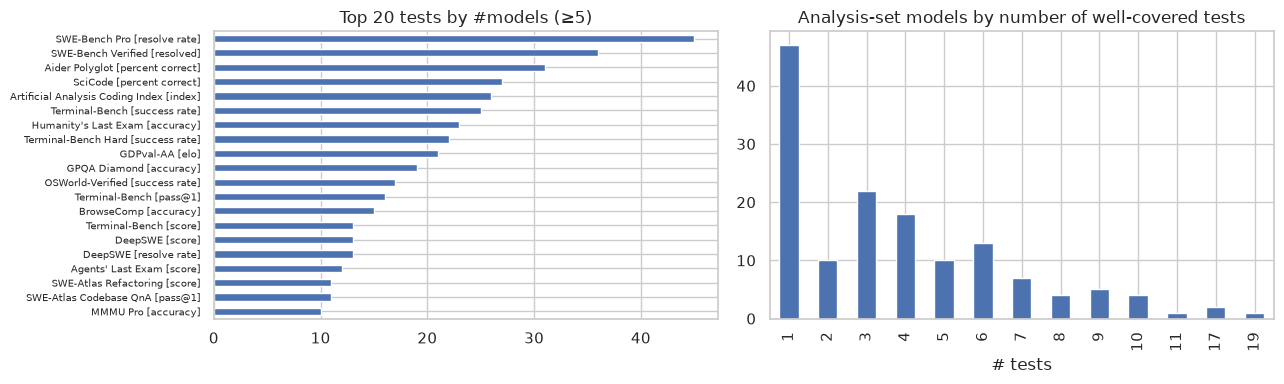

In [21]:
bench_hb = bench[bench.higher_is_better]
test_cov = bench_hb.groupby(["benchmark_clean", "metric_clean"]).model_id.nunique().sort_values(ascending=False)
MIN_MODELS = 5
good_tests = test_cov[test_cov >= MIN_MODELS]
print(f"benchmark/metric tests: {len(test_cov)} | covering ≥{MIN_MODELS} models: {len(good_tests)}")

priced = m[m.has_valid_price]
analysis = priced[priced.model_id.isin(bench_hb.model_id)]
tests_per_model = (bench_hb.set_index(["benchmark_clean", "metric_clean"]).loc[good_tests.index]
                   .reset_index().groupby("model_id").size())
analysis_good = analysis[analysis.model_id.isin(tests_per_model.index)]
print(f"text LLMs: {len(m)} | with valid price: {len(priced)} | + ≥1 benchmark: {len(analysis)} | "
      f"+ ≥1 well-covered test: {len(analysis_good)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
good_tests.head(20).iloc[::-1].plot.barh(ax=ax[0])
ax[0].set_title(f"Top 20 tests by #models (≥{MIN_MODELS})"); ax[0].set_ylabel("")
ax[0].set_yticks(range(min(20, len(good_tests))))
ax[0].set_yticklabels([f"{b} [{mt}]" for b, mt in good_tests.head(20).index[::-1]], fontsize=7)
tests_per_model.reindex(analysis_good.model_id).value_counts().sort_index().plot.bar(ax=ax[1])
ax[1].set_title("Analysis-set models by number of well-covered tests")
ax[1].set_xlabel("# tests"); plt.tight_layout(); plt.show()

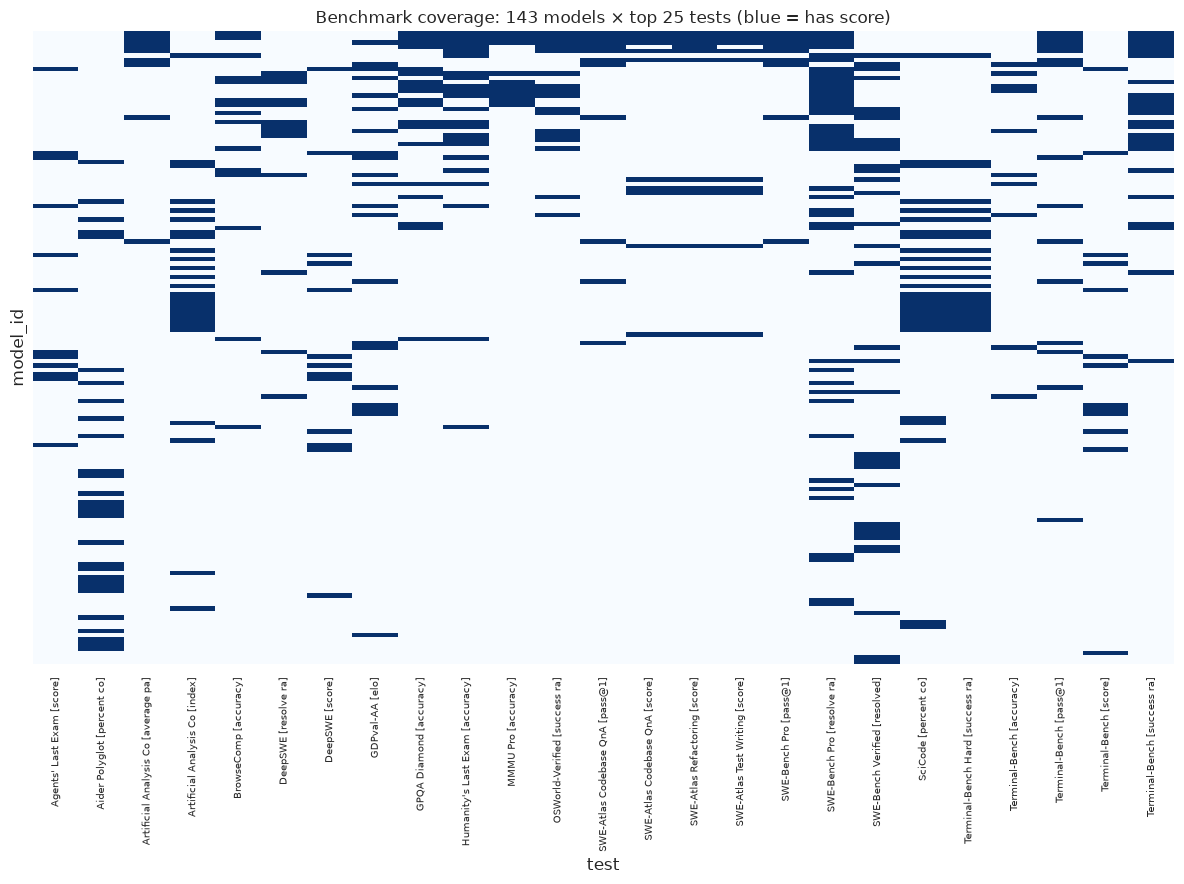

share of the matrix that is filled: 12.5%


In [22]:
# Coverage heat map: which analysis-set models have which of the top-25 tests
top = good_tests.head(25).index
mat = (bench_hb.set_index(["benchmark_clean", "metric_clean"]).loc[top].reset_index()
       .assign(test=lambda d: d.benchmark_clean.str[:22] + " [" + d.metric_clean.str[:10] + "]")
       .pivot_table(index="model_id", columns="test", values="score", aggfunc="size", fill_value=0))
mat = mat.loc[mat.index.isin(analysis_good.model_id)]
mat = mat.loc[mat.sum(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(12, 9))
sns.heatmap(mat.gt(0), cbar=False, cmap="Blues", yticklabels=False)
plt.title(f"Benchmark coverage: {len(mat)} models × top {len(top)} tests (blue = has score)")
plt.xticks(fontsize=7); plt.tight_layout(); plt.show()
print("share of the matrix that is filled:", f"{mat.gt(0).values.mean():.1%}")

**What we found:** The heat map is mostly empty. Each model has scores on only a few tests, and the tests do not overlap much. So **no single benchmark can serve as the performance axis** for RQ1. Choosing one would drop most models. The RQ1 notebook should therefore build a **composite performance score**: convert each score to a percentile within its test (only well-covered tests), then average per model. It should also report how many tests each model's score is based on.

## Step 10 · Validation report and clean outputs
The report collects every check from this notebook in one table: what was checked, whether it passed, how many rows it affected, and what we did. "Passed = True" with affected rows > 0 means the issue was **expected and handled**, for example the non-text models we dropped on purpose.

The clean tables are saved as CSV for the next notebooks:

| File | Contents | Used by |
|---|---|---|
| `clean_models.csv` | text LLMs + flags (`has_valid_price`) | RQ1, RQ2, RQ4 |
| `clean_benchmarks.csv` | one best score per (model, benchmark, metric), canonical names, direction and date flags | RQ1, RQ2, RQ4 |
| `clean_catalog.csv` | text-mode catalog, deduplicated, with `is_free` / `is_deprecated` | RQ3, RQ4 |
| `clean_price_history.csv` | repaired, gap-filled weekly series with `spike_fixed`, `extreme_jump`, `imputed`, `eligible_for_trend` | RQ3, RQ4 |
| `clean_offerings.csv` | provider offers with `is_free` / `is_text_llm` | RQ4 |
| `validation_report.csv` | this report | documentation |

In [23]:
rep = pd.DataFrame(report)
print(f"checks: {len(rep)} | clean passes: {(rep.passed & (rep.rows_affected == 0)).sum()} | "
      f"handled issues: {(rep.passed & (rep.rows_affected > 0)).sum()} | open failures: {(~rep.passed).sum()}")
rep

checks: 49 | clean passes: 25 | handled issues: 24 | open failures: 0


,table,check,passed,rows_affected,action
0,database,SQLite integrity_check,True,0,none
1,database,foreign-key violations,True,0,none
2,labs,primary key ['lab'] unique,True,0,none
3,providers,primary key ['provider_id'] unique,True,0,none
4,models,primary key ['model_id'] unique,True,0,none
5,catalog_models,primary key ['model_id'] unique,True,0,none
6,provider_offerings,"primary key ['provider_id', 'offering_id'] unique",True,0,none
7,price_history,"primary key ['week_start', 'provider', 'model_...",True,0,none
8,catalog_models,row parity with ai_models_2026.csv,True,0,none
9,price_history,row parity with ai_model_price_history.csv,True,0,none


In [24]:
models_out = m.drop(columns=["text_output", "non_llm_name"])
ph_out = ph.assign(week_start=ph.week_start.dt.strftime("%Y-%m-%d"))
outputs = {"clean_models.csv": models_out, "clean_benchmarks.csv": bench,
           "clean_catalog.csv": c.drop(columns=["name_key"]), "clean_price_history.csv": ph_out,
           "clean_offerings.csv": offerings, "validation_report.csv": rep}
for name, df in outputs.items():
    df.to_csv(os.path.join(OUT_DIR, name), index=False)
    print(f"{name:28s} {len(df):>8,} rows")

# Re-load test: files read back with the same shape and no duplicate keys
assert not pd.read_csv(os.path.join(OUT_DIR, "clean_models.csv")).model_id.duplicated().any()
chk = pd.read_csv(os.path.join(OUT_DIR, "clean_price_history.csv"))
assert not chk.duplicated(subset=["week_start", "provider", "model_id"]).any()
assert chk[["input_price_per_1m_tokens", "output_price_per_1m_tokens"]].notna().all().all()
cb = pd.read_csv(os.path.join(OUT_DIR, "clean_benchmarks.csv"))
assert not cb.duplicated(subset=["model_id", "benchmark_clean", "metric_clean"]).any()
assert cb.benchmark_clean.map(bench_key).nunique() == cb.benchmark_clean.nunique()   # no alias groups left
print("\nre-load checks passed ✔")

if IN_COLAB:
    import shutil
    shutil.make_archive("clean_data", "zip", OUT_DIR)
    files.download("clean_data.zip")

clean_models.csv                  411 rows
clean_benchmarks.csv              977 rows
clean_catalog.csv               2,803 rows


clean_price_history.csv       162,072 rows
clean_offerings.csv             8,427 rows
validation_report.csv              49 rows



re-load checks passed ✔


In [25]:
# Numbers for the conclusion
print(f"Text LLMs kept:                         {len(m)} of {len(raw['models'])}")
print(f"  with a valid price:                   {m.has_valid_price.sum()}")
print(f"  + ≥1 benchmark (RQ1 analysis set):    {len(analysis)}")
print(f"  + ≥1 test covering ≥{MIN_MODELS} models:          {len(analysis_good)}")
print(f"Distinct benchmarks after merging:      {bench.benchmark_clean.nunique()} (raw {raw['benchmark_results'].benchmark.nunique()})")
print(f"Well-covered tests (≥{MIN_MODELS} models):        {len(good_tests)}")
print(f"Price series (text modes):              {n_series:,}, eligible for trend: {n_series - n_short:,}")
print(f"Open failures in validation report:     {(~rep.passed).sum()}")

Text LLMs kept:                         411 of 448
  with a valid price:                   356
  + ≥1 benchmark (RQ1 analysis set):    147
  + ≥1 test covering ≥5 models:          144
Distinct benchmarks after merging:      168 (raw 180)
Well-covered tests (≥5 models):        43
Price series (text modes):              4,156, eligible for trend: 2,630
Open failures in validation report:     0


## Conclusion · Is the dataset clean and usable?

**Yes, with documented handling.** The database is structurally sound: no corruption, no broken keys, no duplicate primary keys, and an exact match with the source CSVs. Every content issue found was either **fixed** or **flagged**:

| Area | Issue | Handling |
|---|---|---|
| models | image/video/audio, embedding, guard and ASR models mixed in | dropped (not text LLMs) |
| models | free or unlisted models (price 0 or null) | flagged `has_valid_price` |
| benchmarks | one benchmark under several spellings | merged to a canonical name |
| benchmarks | several variant scores per model and benchmark | kept the best reported score |
| benchmarks | scores reported before the model's release | flagged (matters for the RQ4 backtest) |
| catalog | regional duplicates (`azure/eu/…`, `azure/us/…`) | deduplicated to the base entry |
| price history | missing prices, one-week spikes, internal gaps | dropped / reverted / forward-filled |
| price history | >10× jumps, very short series | flagged for review / RQ3 eligibility |

**Remaining limitations**, to carry into the report:
1. **Benchmark sparsity.** Only part of the text LLMs have both a valid price and a benchmark score, and each has only a few tests. RQ1 must use a composite percentile score and should include a sensitivity check (for example, models with ≥2 tests).
2. **No shared key between the two datasets.** `catalog_models` / `price_history` and `models` are not yet linked. The name-normalization join is the next preparation step, before RQ3 and RQ4.
3. **Flagged, not fixed.** The >10× jumps and pre-release benchmark dates are kept with flags. Later notebooks should state whether they include them.

**Next notebook:** `01_RQ1_tier_clustering.ipynb` reads `clean_models.csv` + `clean_benchmarks.csv`.